# Lab2

### Objective: 
1. Knowing how stereo camera works.
2. Visual odometry: Solving perspective-2-point to find the calibrated camera pose in world reference frame. 
3. Generate point clouds from calibrated stereo images.

Main Python Modules: OpenCV, PIL and Open3D.


### Outcome/Submission
Jupyter notebook with 
- Code to estimate 3D postion of keypoints using stereo image pairs with OpenCV's inbuilt functions.
- Code to find calibrated camera's pose in world frame
- Code to generate pointcloud using the stereo image pairs
- Answers to the questions.

## Stereo Vision
Stereo Vision is the process of extracting 3D information (depth information) from digital images taken by two cameras displaced horizontally from one another to obtain two different views of the same scene. 

### Stereo Vision: Theory 
Given a 3D point in the world P = (X,Y,Z) it will be projected onto an image plane (ignoring lens distortion) at the point p = (x,y) where:

<p style="text-align:center;">$x = f\frac{X}{Z}$</p>

<p style="text-align:center;">$y = f\frac{Y}{Z}$</p>

Here $f$ is the focal length of the camera.

<img title="a title" alt="Alt text" src="centralprojectmodel.png" width="500" height="500">

By mapping a 3D point onto a 2D image information is lost, and the point cannot be retrieved from a single image. However, if we have two images from two cameras, and the position of the two cameras is known (for example, we have a rigid stereo camera rig) the location of the 3D point can be calculated. For simplicity, we will assume we have two stereo cameras parallel to each other, separated by a baseline b.

<img title="a title" alt="Alt text" src="stereogeometry.png" width="500" height="200">

Then the depth Z and the other coordinates X and Y of the point can be calculated (relative to the left
camera) using

<p style="text-align:center;">$Z = f\frac{b}{x_{left} - x_{right}}$         ... Eq 3</p> 

<p style="text-align:center;">$X = x_{left}\frac{Z}{f}$      ... Eq 4</p>  

<p style="text-align:center;">$Y = y_{left}\frac{Z}{f}$      ... Eq 5</p>  


In [2]:
import pickle
with open("Kitti_parameters.pkl", 'rb') as f:
    param = pickle.load(f)

In [3]:
import cv2
import scipy.io
import numpy as np
from PIL import Image

### Steps
1. Read 'Image1Right.png' and 'Image1Left.png' undistored stereo pair images.
2. Detect keypoints and feature descriptors using either SIFT or ORB for the left and right stereo images.
    - Try both or single keypoint detection methods.
    
    ```
    def getSIFTFeatures(gray: np.ndarray, 
                    nfeatures:int = 0, 
                    nOctaveLayers:int = 3,
                    contrastThreshold:float = 0.04,
                    edgeThreshold:int = 10,
                    sigma:float = 1.6,
                    descriptorType:int = cv2.CV_8U
                   ):
        '''
        Function to SIFT extarct kepoints and descriptors using a gray image.

        Use the cv2.SIFT_create function.

        Params:
            gray: Gray image
            Other parameters: https://docs.opencv.org/3.4/d7/d60/classcv_1_1SIFT.html
        ---------
        return:
            kps: Tuple of keypoints
            desc: List of descriptor for each keypoint
        '''
    ```
    
    ```
    def getORBFeatures(gray: np.ndarray, 
                   intnfeatures:int = 500,
                   scaleFactor:float = 1.2,
                   nlevels:int = 8,
                   edgeThreshold:float = 31,
                   firstLevel:int = 0,
                   WTA_K:int = 2,
                   patchSize:int = 31,
                   fastThreshold:int = 20 
                   ):
        '''
        Function to ORB extarct kepoints and descriptors using a gray image.

        Use the cv2.ORB_create fucntion.  

        Params:
            gray: Gray image
            Other parameters: https://docs.opencv.org/4.x/db/d95/classcv_1_1ORB.html
        ---------
        return:
            kps: Tuple of keypoints
            desc: List of descriptor for each keypoint
        '''
    ```

In [4]:
def getSIFTFeatures(gray: np.ndarray, 
                    nfeatures:int = 0, 
                    nOctaveLayers:int = 3,
                    contrastThreshold:float = 0.04,
                    edgeThreshold:int = 10,
                    sigma:float = 1.6,
                    descriptorType:int = cv2.CV_8U
                   ):
    '''
    Function to SIFT extarct kepoints and descriptors using a gray image.
    
    Use the cv2.SIFT_create function.
    
    Params:
        gray: Gray image
        Other parameters: https://docs.opencv.org/3.4/d7/d60/classcv_1_1SIFT.html
    ---------
    return:
        kps: Tuple of keypoints
        desc: List of descriptor for each keypoint
    '''
    sift = cv2.SIFT_create(
        nfeatures=nfeatures,
        nOctaveLayers=nOctaveLayers,
        contrastThreshold=contrastThreshold,
        edgeThreshold=edgeThreshold,
        sigma=sigma,
        descriptorType=descriptorType
    )
    kps, desc = sift.detectAndCompute(gray, None)
    return kps, desc

def getORBFeatures(gray: np.ndarray, 
                   intnfeatures:int = 500,
                   scaleFactor:float = 1.2,
                   nlevels:int = 8,
                   edgeThreshold:float = 31,
                   firstLevel:int = 0,
                   WTA_K:int = 2,
                   patchSize:int = 31,
                   fastThreshold:int = 20 
                   ):
    '''
    Function to ORB extarct kepoints and descriptors using a gray image.
    
    Use the cv2.ORB_create fucntion.  
    
    Params:
        gray: Gray image
        Other parameters: https://docs.opencv.org/4.x/db/d95/classcv_1_1ORB.html
    ---------
    return:
        kps: Tuple of keypoints
        desc: List of descriptor for each keypoint
    '''
    orb = cv2.ORB_create(
        nfeatures=intnfeatures,
        scaleFactor=scaleFactor,
        nlevels=nlevels,
        edgeThreshold=edgeThreshold,
        firstLevel=firstLevel,
        WTA_K=WTA_K,
        patchSize=patchSize,
        fastThreshold=fastThreshold
    )
    kps, desc = orb.detectAndCompute(gray, None)
    return kps, desc

In [5]:
### Keypoint Detection and visualization
#Read the images
image1Right = cv2.imread("Image1Right.png", cv2.IMREAD_GRAYSCALE)
image1Left = cv2.imread("Image1Left.png", cv2.IMREAD_GRAYSCALE)

#display(Image.fromarray(Image1Right))
#display(Image.fromarray(Image1Left))


#Estimate the keypoints and thier descriptors
siftKpsRight, siftDescRight = getSIFTFeatures(image1Right)
siftKpsLeft, siftDescLeft = getSIFTFeatures(image1Left)

orbKpsRight, orbDescRight = getORBFeatures(image1Right)
orbKpsLeft, orbDescLeft = getORBFeatures(image1Left)


3. Draw the keypoints on image and visualize the keypoints

    `cv2.drawKeypoints(gray, kp, img, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)`
    
    <span style="color:Red">Q1</span>. Are there same keypoints on both left and right images?
    
    <span style="color:Red">Q2</span>. What are the properties/elements of the kepoints?

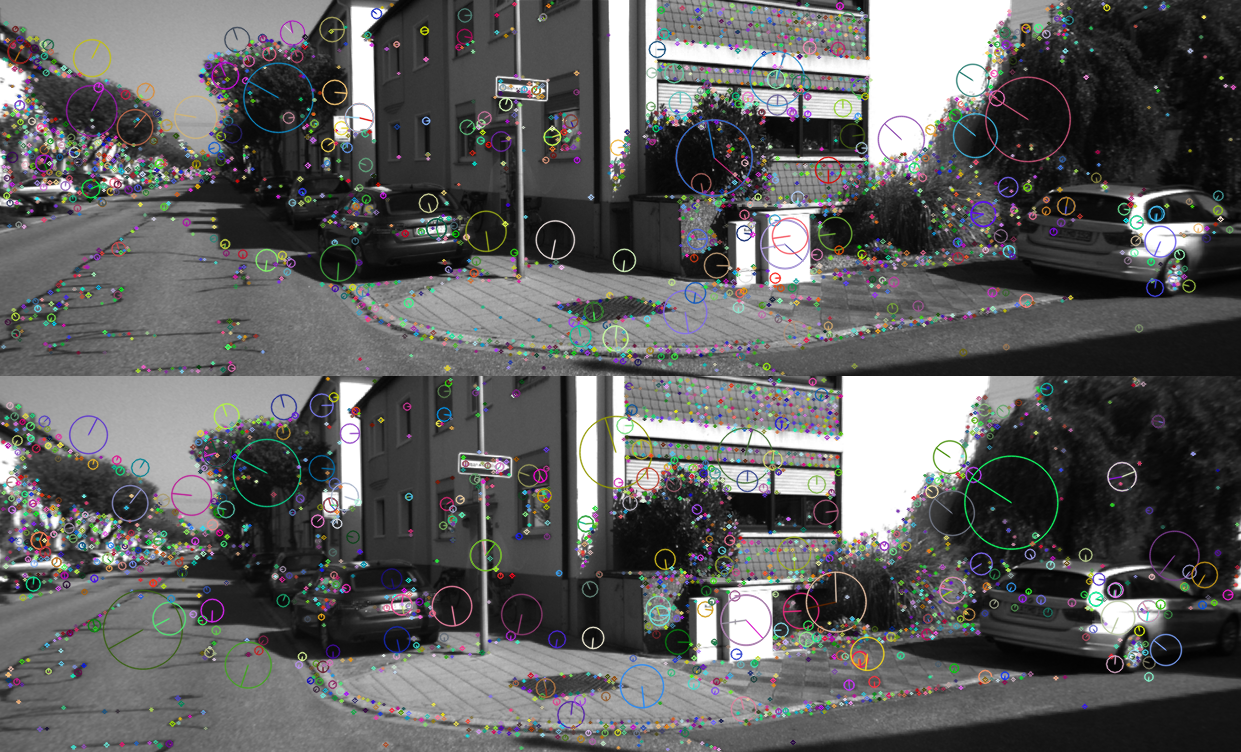

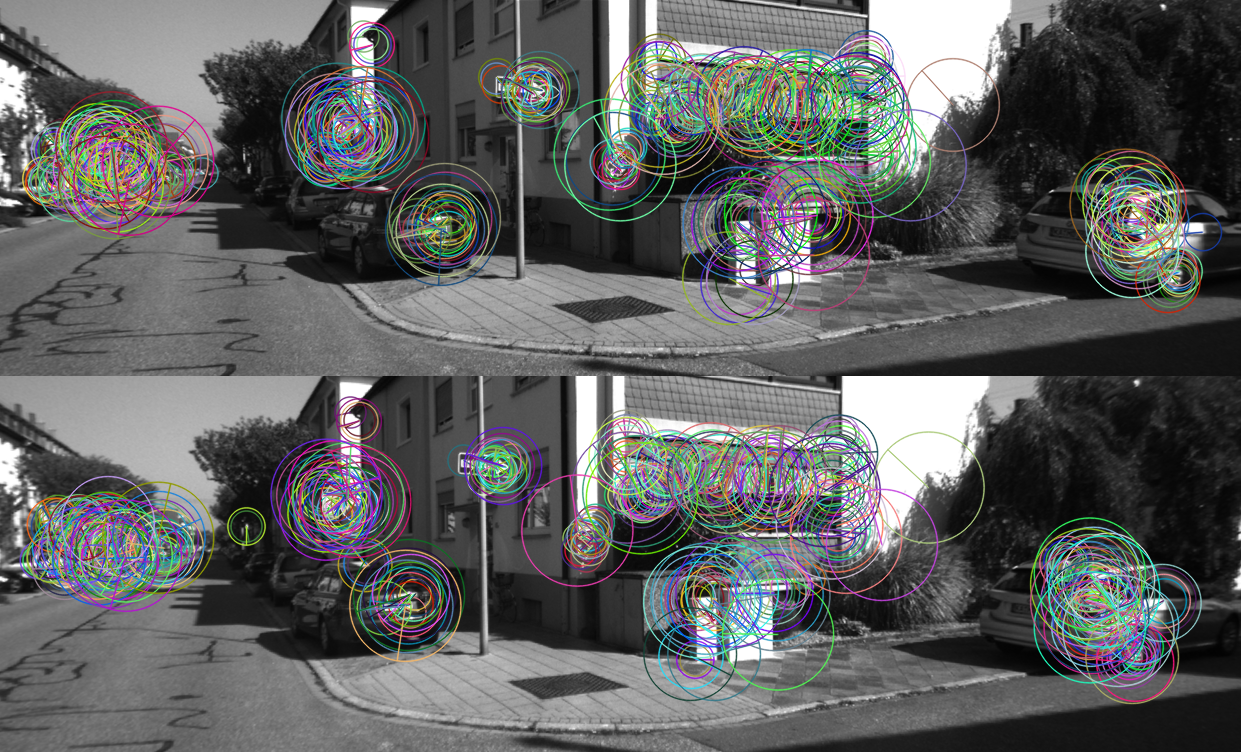

In [6]:
# sift
image1RightSiftKps = cv2.drawKeypoints(image1Right, siftKpsRight, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image1LeftSiftKps = cv2.drawKeypoints(image1Left, siftKpsLeft, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

# orb
image1RightObsKps = cv2.drawKeypoints(image1Right, orbKpsRight, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image1LeftObsKps = cv2.drawKeypoints(image1Left, orbKpsLeft, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

# Join the left and right images along the height and visualize it
image1SiftKps = np.vstack((image1LeftSiftKps, image1RightSiftKps)) # np.vstack stacks the image vertically (= along the height)
display(Image.fromarray(image1SiftKps))

image1ObsKps = np.vstack((image1LeftObsKps, image1RightObsKps)) # np.vstack stacks the image vertically (= along the height)
display(Image.fromarray(image1ObsKps))    

<span style="color:Red">Q1</span>: No, but it seems like they correspond to the same physical feature, but the exact position differs.
    
<span style="color:Red">Q2</span>: Pt (Position), size, angle, response, ocatve, class_id. They are acessable with kps.pt, kps.size,...

4. Match the keypoints using OpenCV's Brute Force matcher module (cv2.BFMatcher)
    - Try out different matching criterias (cv2.NORM_*)
5. Draw the matches and visualize.
    
    `cv2.drawMatches(img_left, kps_left, img_right, kps_right, matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)`
    
    <span style="color:Red">Q3</span>. Which matching criteria do you think work better and why?
    
    <span style="color:Red">Q4</span>. List few ways to reduce the incorrect matches or which keypoint features would you use for select strong keypoints for matching.

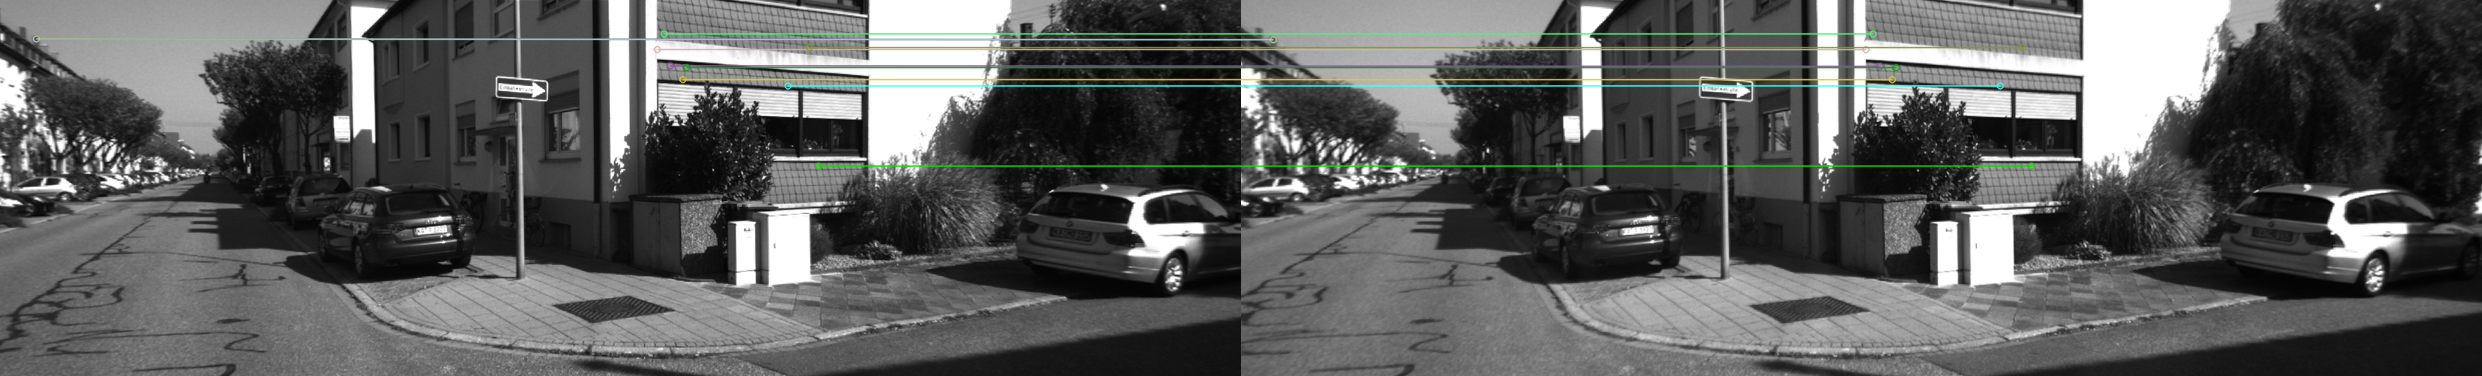

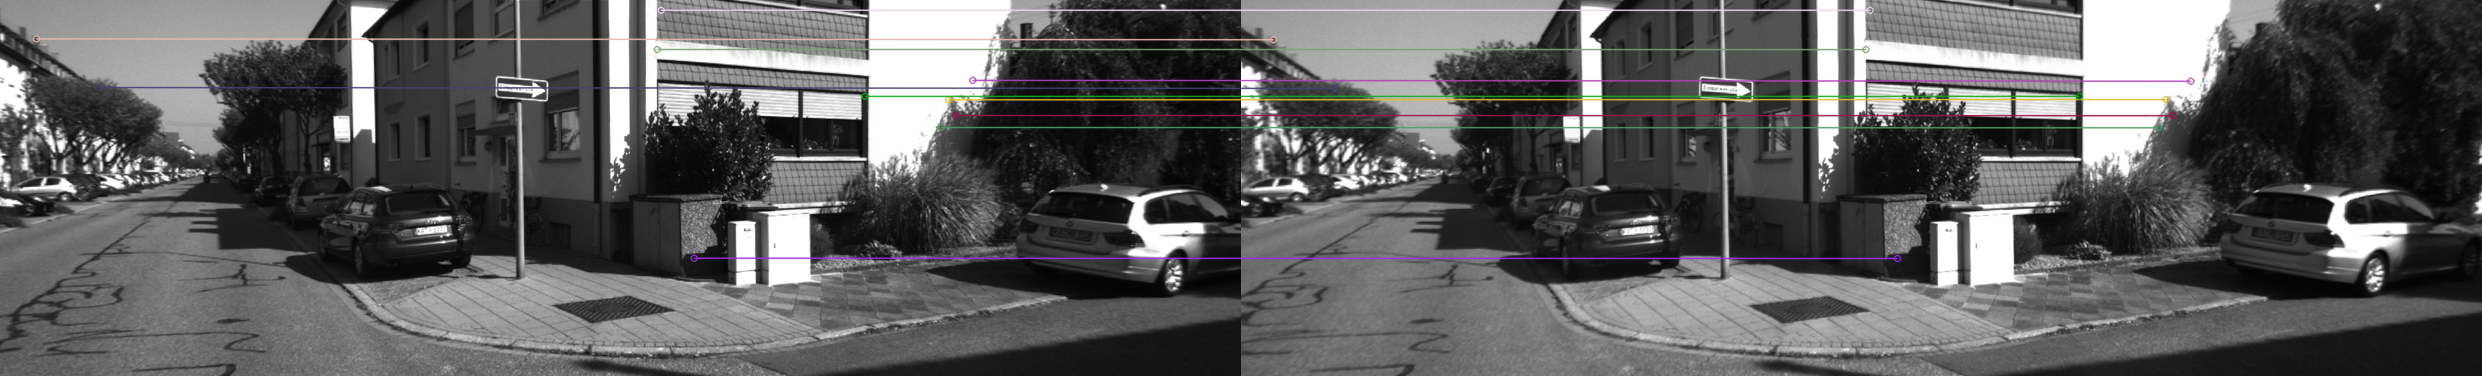

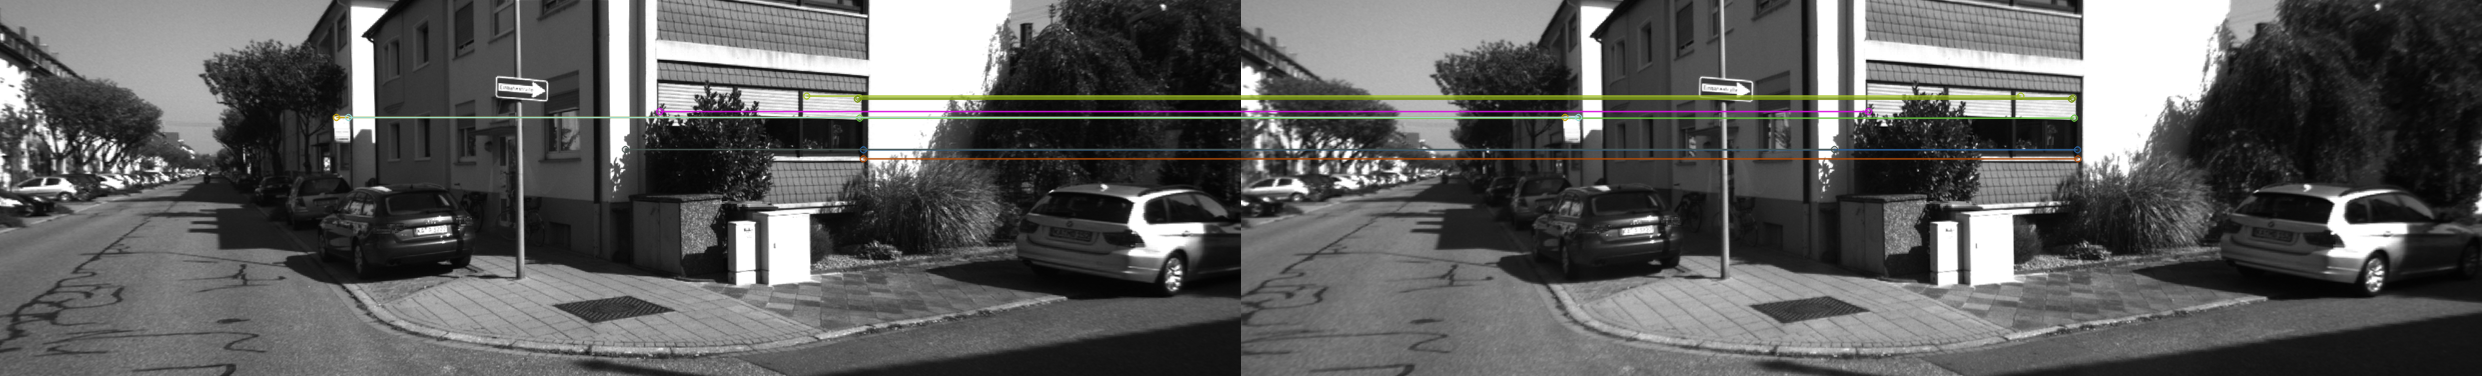

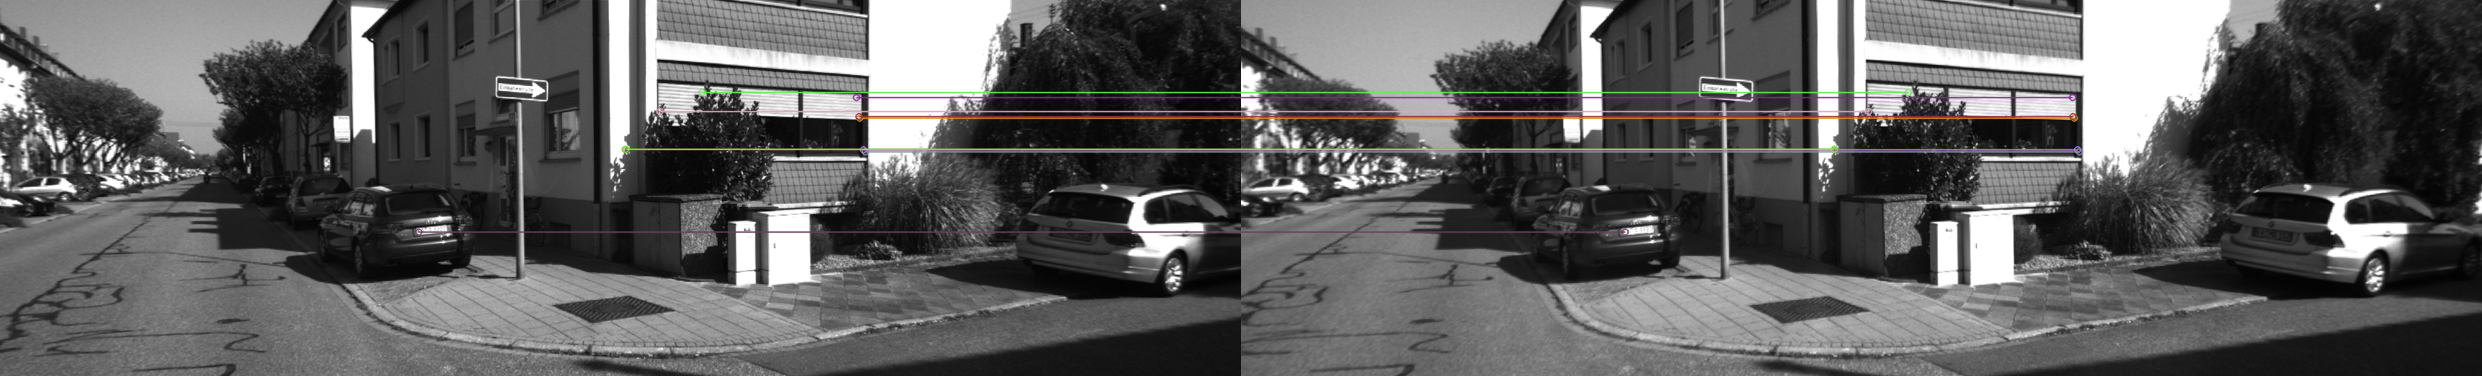

In [7]:
def matchKeypointsAndVisualize(normType, descLeft, descRight, kpsLeft, kpsRight):
    ...

    ### Keypoint Matching and Visualization
    # Match keypoints using cv2.BFMatcher
    bf = cv2.BFMatcher(normType=normType)#, crossCheck=True)
    matches = bf.match(descLeft, descRight)
    

    # Select top 10 matches using distance
    matches = sorted(matches, key=lambda x: x.distance)  # Sort matches by distance
    matches =  matches[:10]

    # Visualize the matches
    imgage1Matches = cv2.drawMatches(
            image1Left, kpsLeft, image1Right, kpsRight, matches, None,
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )

    display(Image.fromarray(imgage1Matches)) 

# sift
matchKeypointsAndVisualize(cv2.NORM_L2, siftDescLeft, siftDescRight, siftKpsLeft, siftKpsRight)
matchKeypointsAndVisualize(cv2.NORM_HAMMING, siftDescLeft, siftDescRight, siftKpsLeft, siftKpsRight)

# orb
matchKeypointsAndVisualize(cv2.NORM_L2, orbDescLeft, orbDescRight, orbKpsLeft, orbKpsRight)
matchKeypointsAndVisualize(cv2.NORM_HAMMING, orbDescLeft, orbDescRight, orbKpsLeft, orbKpsRight)


<span style="color:Red">Q3</span>: Norm_L2 works better for sift, because L2 calculates Euclidean distance, which works well, because sift is floating-point descriptor that captures gradient-based features. NORM_HAMMING works better for orb, because it calculates Hamming distance, which works well, because orb is a binary descriptor.
    
<span style="color:Red">Q4</span>: You can use the properties/elemets of the keypoints like kps.response to only use keypoints with high response value. Another option would be to remove matches with a large distance.

6. Calculate the 3D position of the top 20 matches in left image using Eqs 3-5. Stereo camera parameters are provided in "Kitti_parameters.pkl"

Note: There are better and more sophisticated ways to estimate 3D position of the matches in stereo images. *[Triangulation](https://en.wikipedia.org/wiki/Triangulation_(computer_vision))*

<p style="text-align:center;">$Z = f\frac{b}{x_{left} - x_{right}}$         ... Eq 3</p> 

<p style="text-align:center;">$X = x_{left}\frac{Z}{f}$      ... Eq 4</p>  

<p style="text-align:center;">$Y = y_{left}\frac{Z}{f}$      ... Eq 5</p>  

In [8]:
### 2D Keypoint -> 3D Point
def calculateKeypoint3DPosition(kps_left_matches:np.ndarray, 
                                kps_right_matches:np.ndarray,
                                baseline:float,
                                focal:float)->np.ndarray:
    '''
    Calculate the 3D position of the left image keypoints using Eqs 3-5
    
    Params:
        kps_left_matches: Keypoint indices in left images.
        kps_right_matches: Keypoint indices in right images.
        baseline: Distance between stereo camera
        focal: Focal length
    ---------
    Returns:
        points: 3D position of the 
    '''
    points_3d = []

    for kp_left, kp_right in zip(kps_left_matches, kps_right_matches):
        # Get keypoint positions in the left and right images
        x_left, y_left = kp_left
        x_right, y_right = kp_right
        
        # Eqs 3
        disparity = x_left - x_right
        
        if disparity == 0:
            # Skip if disparity is zero (it would cause a division by zero error)
            continue
        
        Z = focal * (baseline / disparity) # Eqs 3
        X = x_left * (Z / focal) # Eqs 4
        Y = y_left * (Z / focal) # Eqs 5
        
        points_3d.append([X, Y, Z])
    
    return np.array(points_3d)
    

In [9]:
def matchKeypoints(normType, descLeft, descRight, kpsLeft, kpsRight):
    ...

    ### Keypoint Matching and Visualization
    # Match keypoints using cv2.BFMatcher
    bf = cv2.BFMatcher(normType=normType)#, crossCheck=True)
    matches = bf.match(descLeft, descRight)
    

    # Select top 10 matches using distance
    matches = sorted(matches, key=lambda x: x.distance)  # Sort matches by distance
    matches = matches[:20]

    kpsLeftMatches = np.array([kpsLeft[m.queryIdx].pt for m in matches])
    kpsRightMatches = np.array([kpsRight[m.trainIdx].pt for m in matches])

    return kpsLeftMatches, kpsRightMatches

# Estimate 3D position of best matches
#print(param)

focal = param['Camera_Parameters']['K'][0, 0]
baseline = abs(param['PoseCamera2'][0, 3])

siftkpsLeftMatches, siftkpsRightMatches = matchKeypoints(cv2.NORM_L2, siftDescLeft, siftDescRight, siftKpsLeft, siftKpsRight)
sift3DPositions = calculateKeypoint3DPosition(siftkpsLeftMatches, siftkpsRightMatches, baseline, focal)
print(sift3DPositions)

orbkpsLeftMatches, orbkpsRightMatches = matchKeypoints(cv2.NORM_HAMMING, orbDescLeft, orbDescRight, orbKpsLeft, orbKpsRight)
orb3DPositions = calculateKeypoint3DPosition(orbkpsLeftMatches, orbkpsRightMatches, baseline, focal)
print(orb3DPositions)


[[11.08673115  0.55727593 12.0089287 ]
 [10.93746433  0.81604207 11.97118771]
 [15.66193206  0.91267929 13.91390435]
 [ 4.83651506  5.17535981 96.74945514]
 [ 4.83651506  5.17535981 96.74945514]
 [11.52114126  1.12466747 12.3632416 ]
 [14.67852671  1.59301828 13.39765029]
 [15.71587748  3.18162193 13.81145553]
 [11.61562312  1.34581544 12.23540272]
 [11.71091605  1.1445197  12.26700097]
 [ 9.87371202  3.66759168 10.23173853]
 [15.72050467  1.67653206 13.80127249]
 [16.25712795  1.71850327 13.96627115]
 [15.16072746  2.13855601 13.77648038]
 [12.05744824  1.17735547 12.49493973]
 [22.86045696  1.87848788 16.90269572]
 [11.07893745  0.16318214 12.05485015]
 [21.74570291  2.6185639  16.36715022]
 [13.25195866  1.40481449 11.46825188]
 [20.23911233  1.8999714  17.68395324]]
[[17.25010312  2.98444699 14.36971562]
 [10.98274889  1.85035436 11.97474489]
 [10.4921875   2.5013375  12.0677951 ]
 [17.48344268  2.39298526 14.62765072]
 [17.2316952   3.01657959 14.32546717]
 [10.36598229  2.4671435

## Visual Odomtery

[Perspective-n-Point](https://en.wikipedia.org/wiki/Perspective-n-Point): Finding the calibrated camera pose (translation and rotation) given the 3D position of points in world reference frame and their 2D pixel coordinate in the camera image. 

We will use [OpenCV's solvePnP](https://docs.opencv.org/4.x/d5/d1f/calib3d_solvePnP.html)* functions and only single step.

### Steps:
1. Load Image2Left.png.
2. Calculate the keypoints and their descriptors with earlier used keypoint detection algorithm.
3. Match the keypoints of Image2Left.png and Images1Left.png.
4. Select the keypoints in Image2Left.png for which 3D position are known.
5. Try OpenCV's solvePnP fucntion's to estimate the calibrated camera pose (Image2Left.png) wrt the reference frame of ImageLeft1.png.
    
    <span style="color:Red">Q5</span>. Do you think the estimated pose is correct?
    
    <span style="color:Red">Q6</span>. What is the translation and rotation error? 
    
    <span style="color:Red">Q7</span>. List few ways on how to imporve the pose estimation.

In [10]:
image2Left = cv2.imread("Image2Left.png", cv2.IMREAD_GRAYSCALE) #1

siftKpsLeft2, siftDescLeft2 = getSIFTFeatures(image2Left) #2
#orbKpsLeft2, orbDescLeft2 = getORBFeatures(image2Left)

bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.match(siftDescLeft, siftDescLeft2) #3

matchesKnown3DPositions = [m for m in matches if m.queryIdx < len(sift3DPositions)] # 4

kpsLeft2Matches = np.array([siftKpsLeft2[m.trainIdx].pt for m in matchesKnown3DPositions])
points3D = np.array([sift3DPositions[m.queryIdx] for m in matchesKnown3DPositions])

print(points3D)
success, rotationVector, translationVector = cv2.solvePnP(points3D, kpsLeft2Matches, param['Camera_Parameters']['K'], None)

print(success)
print(rotationVector)
print(translationVector)

[[11.08673115  0.55727593 12.0089287 ]
 [10.93746433  0.81604207 11.97118771]
 [15.66193206  0.91267929 13.91390435]
 [ 4.83651506  5.17535981 96.74945514]
 [ 4.83651506  5.17535981 96.74945514]
 [11.52114126  1.12466747 12.3632416 ]
 [14.67852671  1.59301828 13.39765029]
 [15.71587748  3.18162193 13.81145553]
 [11.61562312  1.34581544 12.23540272]
 [11.71091605  1.1445197  12.26700097]
 [ 9.87371202  3.66759168 10.23173853]
 [15.72050467  1.67653206 13.80127249]
 [16.25712795  1.71850327 13.96627115]
 [15.16072746  2.13855601 13.77648038]
 [12.05744824  1.17735547 12.49493973]
 [22.86045696  1.87848788 16.90269572]
 [11.07893745  0.16318214 12.05485015]
 [21.74570291  2.6185639  16.36715022]
 [13.25195866  1.40481449 11.46825188]
 [20.23911233  1.8999714  17.68395324]]
True
[[8.94038623]
 [8.13313108]
 [4.35624786]]
[[-16.44412295]
 [ -1.85074688]
 [ 10.94667832]]


<span style="color:Red">Q5</span>: No, because it depends on the quality of matches between the keypoints in the two images, which we have, but our quantaty is to low for good results.
   
<span style="color:Red">Q6</span>: The translation error is the Euclidean distance between the true position and the estimated position. The rotation error is the angle of the relative rotation matrix between the true orientation and the estimated orientation.
    
<span style="color:Red">Q7</span>: 
- Increase the number of high-quality matches
- Refine camera intrinsics
- Improve keypoint distribution

## Converting Stereo Image to Pointcloud

Stereo images could be used to estimate the 3D point cloud. We will use OpenCV's [Block Matching](https://docs.opencv.org/3.4/d9/dba/classcv_1_1StereoBM.html) and [Semi-global Block Matching](https://docs.opencv.org/4.5.0/d2/d85/classcv_1_1StereoSGBM.html) algorithm to estimate the [disparity map](https://en.wikipedia.org/wiki/Binocular_disparity) (not depth map). 

**Disparity map:** The disparity is the distance between these two sets of stereo image coordinates for the same scene. In a disparity map, each pixel value corresponds to the difference in the horizontal position (disparity) of a corresponding point between the left and right images of a stereo camera pair. Pixels that are closer to the camera have a larger disparity value, while pixels that are further away have a smaller disparity value.

### Steps:
1. Load Images1Left.png and Images1Right.png
2. Estimate disparity map using OpenCV's block matching or semi-global block matching algorithms.
3. Reproject the left image to 3D points using disparity map and projection matrix using OpenCV's builtin fucntion.
    - Write projection matrix from provided camera parameters.
    - Select the valid points
4. Visualize the point cloud.
    ```
    import open3d as o3d
    
    pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points)) #point = N*3 numpy array
    pcd.colors = o3d.utility.Vector3dVector(colors) #colors = N*3 numpy array (normalized 0-1)
    
    o3d.visualization.draw_geometries([pcd])
    ```
    <span style="color:Red">Q8</span>. Is the point cloud correct?
    
5. Fine tune the algorithms's disparity parameter until you accept the results.
    
    <span style="color:Red">Q9</span>. What are the finalized/fine-tuned parameters? What approach you used for fine-tuning?
    
Hint: [Reference Code](https://github.com/opencv/opencv/blob/master/samples/python/stereo_match.py)

In [ ]:
# reference code
window_size = 3
min_disp = 16
num_disp = 112-min_disp
stereo = cv2.StereoSGBM_create(minDisparity = min_disp,
    numDisparities = num_disp,
    blockSize = 16,
    P1 = 8*3*window_size**2,
    P2 = 32*3*window_size**2,
    disp12MaxDiff = 1,
    uniquenessRatio = 10,
    speckleWindowSize = 100,
    speckleRange = 32
)
#2
disparity = stereo.compute(image1Left, image1Right).astype(np.float32) / 16.0

#3
h, w = image1Left.shape[:2]
Q = np.float32([
    [1, 0, 0, -w/2],
    [0, -1, 0, h/2],
    [0, 0, 0, focal],
    [0, 0, 1, 0]
])

points3D = cv2.reprojectImageTo3D(disparity, Q)
colors = cv2.cvtColor(image1Left, cv2.COLOR_BGR2RGB)

# filter valid points
mask = disparity > disparity.min()
points3D = points3D[mask]
colors = colors[mask]

#4
import open3d as o3d # using python 3.13, but open3d is only available in 3.11

print("Type of points3D:", type(points3D))
print("Shape of points3D:", points3D.shape)
print("Number of NaNs:", np.isnan(points3D).sum())
print("Number of Infs:", np.isinf(points3D).sum())
#points3D = points3D[~np.isnan(points3D).any(axis=1)]
#points3D = points3D[~np.isinf(points3D).any(axis=1)]   
points3D = points3D[::5000]
print(points3D.shape)
points3D = np.array(points3D)
print(type(points3D))
points = points3D.astype(np.float32)

print("Data type of points:", points3D.dtype)

if points3D.shape[0] == 0:
    print("Error: No valid points in points3D")
pcd = o3d.geometry.PointCloud()
#pcd.points = o3d.utility.Vector3dVector(points3D)
#pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points3D)) #point = N*3 numpy array
#pcd.colors = o3d.utility.Vector3dVector(colors) #colors = N*3 numpy array (normalized 0-1)

#o3d.visualization.draw_geometries([pcd])

# Create a small point cloud to test
test_points = np.random.rand(100, 3)  # 100 random points
print("Type of test_points:", type(test_points))
print("Data type of points:", test_points.dtype)

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(test_points)

# Visualize the point cloud
o3d.visualization.draw_geometries([pcd])

#print(test_points)
print(points3D)


: 

<span style="color:Red">Q8</span>: Yes.
    

    
<span style="color:Red">Q9</span>: See above. I used ...

## Monocular Depth Estimation
Interested people can check out recent deep learning methods for monocular disparity or depth estimations method.

1. [Metric3D](https://github.com/YvanYin/Metric3D)
2. [Zeo-Depth](https://github.com/isl-org/ZoeDepth)

There are many other methods to try.